Размер датасета:
(748, 5)

Первые строки:
   Recency  Frequency  Monetary  Time  Class
0        2         50     12500    98      0
1        0         13      3250    28      0
2        1         16      4000    35      0
3        2         20      5000    45      0
4        1         24      6000    77      1

Информация о данных:
<class 'pandas.DataFrame'>
RangeIndex: 748 entries, 0 to 747
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Recency    748 non-null    int64
 1   Frequency  748 non-null    int64
 2   Monetary   748 non-null    int64
 3   Time       748 non-null    int64
 4   Class      748 non-null    int64
dtypes: int64(5)
memory usage: 29.3 KB

Баланс целевого признака:
Class
1    0.762
0    0.238
Name: proportion, dtype: float64

Пропуски:
Recency      0
Frequency    0
Monetary     0
Time         0
Class        0
dtype: int64

Описание числовых признаков:
           count         mean          std    min  

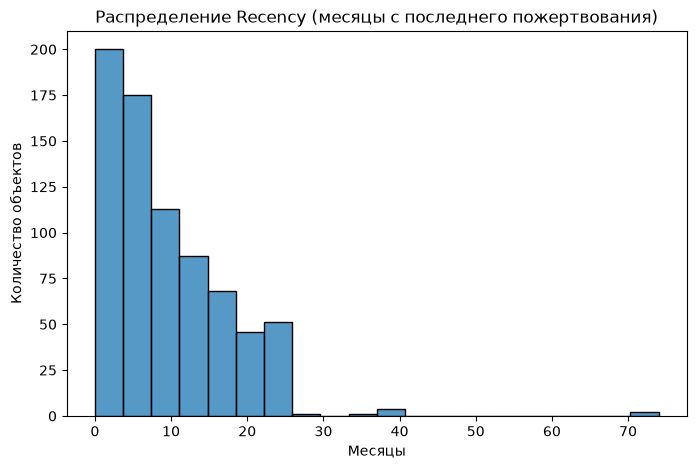

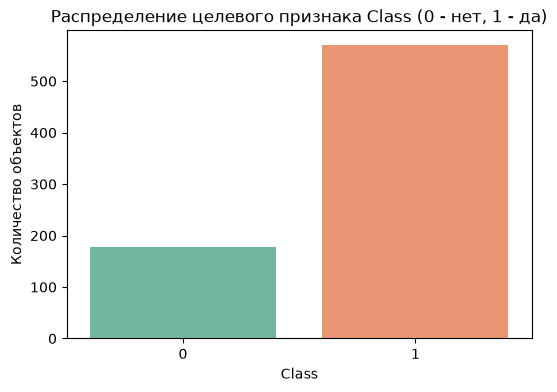

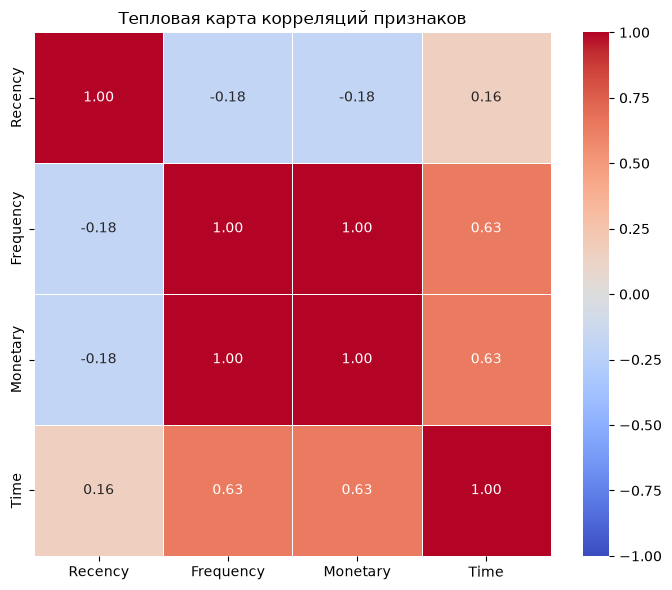


Результаты кросс-валидации (Топ-3):
   metric  k  f1_mean   f1_std
manhattan 17 0.877920 0.010470
euclidean 17 0.877140 0.012480
euclidean 21 0.877098 0.008402

Лучшие параметры: metric=manhattan, k=17

--- Результаты k-NN на тестовой выборке ---
Accuracy:  0.7778
Precision: 0.804
Recall:    0.9357
F1-score:  0.8649

Матрица ошибок:
 [[ 15  39]
 [ 11 160]]


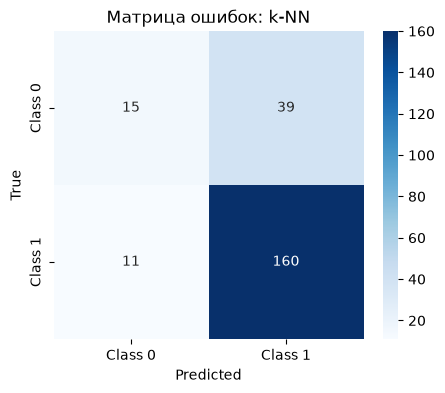


--- Результаты Baseline (DummyClassifier) ---
Accuracy:  0.76
F1-score:  0.8636

--- Влияние масштабирования ---
Без масштабирования -> Accuracy: 0.7556 | F1: 0.8549
С масштабированием  -> Accuracy: 0.7778 | F1: 0.8649


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, confusion_matrix, classification_report
)

# 1. Загрузка датасета
data = fetch_openml(data_id=1464, as_frame=True, parser='auto')
df = data.frame

# Переименование колонок для удобства и приведение целевой переменной к 0 и 1
df.columns = ['Recency', 'Frequency', 'Monetary', 'Time', 'Class']
# В исходных данных Class: '1' - сдавал, '2' - не сдавал. Преобразуем: 1 -> 1, 2 -> 0
df['Class'] = (df['Class'] == '1').astype(int)

X = df.drop(columns=['Class'])
y = df['Class']

# 2. EDA
# 2. EDA (Разведочный анализ данных)
print('Размер датасета:')
print(df.shape)

print('\nПервые строки:')
print(df.head())

print('\nИнформация о данных:')
df.info()

print('\nБаланс целевого признака:')
print(y.value_counts(normalize=True).round(3))

print('\nПропуски:')
print(df.isna().sum())

print('\nОписание числовых признаков:')
print(df.describe().T)

# Визуализация распределения Recency
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Recency', bins=20, kde=False)
plt.title('Распределение Recency (месяцы с последнего пожертвования)')
plt.xlabel('Месяцы')
plt.ylabel('Количество объектов')
plt.show()

# Визуализация целевого признака
plt.figure(figsize=(6, 4))
sns.countplot(x=y, hue=y, palette='Set2', legend=False)
plt.title('Распределение целевого признака Class (0 - нет, 1 - да)')
plt.xlabel('Class')
plt.ylabel('Количество объектов')
plt.show()

# Корреляционная матрица
plt.figure(figsize=(7, 6))
sns.heatmap(
    X.corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    vmin=-1, vmax=1
)
plt.title('Тепловая карта корреляций признаков')
plt.tight_layout()
plt.show()

# 3. Разделение на train и test (70/30)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 4. Подготовка данных
def make_preprocessor(scale=True):
    steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale:
        steps.append(('scaler', StandardScaler()))
    return Pipeline(steps)

# 5. Кросс-валидация и подбор K
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
k_range = list(range(3, 22, 2))
dist_metrics = ['euclidean', 'manhattan']
results = []

for metric in dist_metrics:
    for k in k_range:
        model = Pipeline([
            ('prepare', make_preprocessor(scale=True)),
            ('knn', KNeighborsClassifier(n_neighbors=k, metric=metric))
        ])
        scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1', n_jobs=-1)
        results.append((metric, k, scores.mean(), scores.std()))

results_df = pd.DataFrame(results, columns=['metric', 'k', 'f1_mean', 'f1_std'])
results_df = results_df.sort_values('f1_mean', ascending=False)

print('\nРезультаты кросс-валидации (Топ-3):')
print(results_df.head(3).to_string(index=False))

best_k = int(results_df.iloc[0]['k'])
best_metric = results_df.iloc[0]['metric']
print(f'\nЛучшие параметры: metric={best_metric}, k={best_k}')

# 6. Обучение итоговой модели k-NN
knn = Pipeline([
    ('prepare', make_preprocessor(scale=True)),
    ('knn', KNeighborsClassifier(n_neighbors=best_k, metric=best_metric))
])
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

# 7. Оценка качества k-NN
print('\n--- Результаты k-NN на тестовой выборке ---')
print('Accuracy: ', round(accuracy_score(y_test, y_pred), 4))
print('Precision:', round(precision_score(y_test, y_pred, zero_division=0), 4))
print('Recall:   ', round(recall_score(y_test, y_pred, zero_division=0), 4))
print('F1-score: ', round(f1_score(y_test, y_pred, zero_division=0), 4))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print('\nМатрица ошибок:\n', cm)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Class 0', 'Class 1'], 
            yticklabels=['Class 0', 'Class 1'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Матрица ошибок: k-NN')
plt.show()

# 8. Baseline: DummyClassifier
baseline = Pipeline([
    ('prepare', make_preprocessor(scale=True)),
    ('dummy', DummyClassifier(strategy='most_frequent'))
])
baseline.fit(X_train, y_train)
y_base = baseline.predict(X_test)

print('\n--- Результаты Baseline (DummyClassifier) ---')
print('Accuracy: ', round(accuracy_score(y_test, y_base), 4))
print('F1-score: ', round(f1_score(y_test, y_base, zero_division=0), 4))

# 9. Сравнение с масштабированием и без него
knn_no_scale = Pipeline([
    ('prepare', make_preprocessor(scale=False)),
    ('knn', KNeighborsClassifier(n_neighbors=best_k, metric=best_metric))
])
knn_no_scale.fit(X_train, y_train)
y_no_scale = knn_no_scale.predict(X_test)

print('\n--- Влияние масштабирования ---')
print('Без масштабирования -> Accuracy:', round(accuracy_score(y_test, y_no_scale), 4), 
      '| F1:', round(f1_score(y_test, y_no_scale, zero_division=0), 4))
print('С масштабированием  -> Accuracy:', round(accuracy_score(y_test, y_pred), 4), 
      '| F1:', round(f1_score(y_test, y_pred, zero_division=0), 4))